# Vlícovací a kontrolní body: přesnost transformace na skutečném bodovém poli

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/gcp_accuracy_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Vlícovací body a přesnost](https://openskylab.space/edu_viz_gcp_accuracy.html) · [English version](gcp_accuracy_en.ipynb)

Vizuál simuluje, jak rozmístění vlícovacích bodů a způsob georeferencování ovlivní přesnost mapy z dronu. Tady stejné principy ověříš na skutečných bodech bodového pole ČÚZK: každý bod má souřadnice z GNSS v ETRS89 a zároveň souřadnice v S-JTSK a nadmořskou výšku v Bpv. Převod mezi systémy odhadneš z několika vlícovacích bodů a jeho přesnost změříš na ostatních, nezávislých kontrolních bodech. Je to stejná úloha jako georeferencování bloku snímků, jen na území desítek kilometrů.

**Cíl:** odhadnout podobnostní (Helmertovu) transformaci z vlícovacích bodů, porovnat odchylky na vlícovacích a kontrolních bodech pro různé rozmístění, převést elipsoidické výšky na Bpv, posoudit, kolik kontrolních bodů je potřeba, a ukázat, kdy složitější transformace škodí.

**Data:** trigonometrické a zhušťovací body ČÚZK v okolí Prahy se souřadnicemi S-JTSK, výškou Bpv a souřadnicemi ETRS89 (B, L, elipsoidická výška) ze statického měření GNSS, služba BodovaPole (vrstva 2).

**Úkoly:** čtyři. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a body bodového pole

In [1]:
%pip install -q pyproj

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer

CX, CY = -742000, -1045000    # ◀ parametr: střed území v S-JTSK (EPSG:5514, m), Praha
HALF = 30000                  # ◀ parametr: polovina strany území (m)
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/2/query",
                 params={"geometry": f"{CX - HALF},{CY - HALF},{CX + HALF},{CY + HALF}", "geometryType": "esriGeometryEnvelope", "inSR": 5514,
                         "outFields": "CISLO_SMO5,CISLO,NAZEV_KU,Y,X,VYSKA,B,L,HEL", "returnGeometry": "false", "f": "json"}, timeout=120).json()
p = pd.DataFrame([f["attributes"] for f in q["features"]])
for k in ["Y", "X", "VYSKA", "B", "L", "HEL"]:
    p[k] = pd.to_numeric(p[k], errors="coerce")
p = p.dropna(subset=["Y", "X", "VYSKA", "B", "L", "HEL"]).reset_index(drop=True)
# „mapa“: polohy z GNSS v ETRS89 převedené do UTM 33N; „skutečnost“: S-JTSK (osy EPSG:5514: x = −Y, y = −X)
p["E"], p["N"] = Transformer.from_crs(4258, 32633, always_xy=True).transform(p.L.values, p.B.values)
p["sx"], p["sy"] = -p.Y, -p.X
SRC, DST = p[["E", "N"]].values, p[["sx", "sy"]].values
C0 = SRC.mean(axis=0)
print(f"bodů: {len(p)} na území {2 * HALF / 1000:.0f} × {2 * HALF / 1000:.0f} km")
p[["CISLO_SMO5", "CISLO", "NAZEV_KU", "Y", "X", "VYSKA", "B", "L", "HEL"]].head()

bodů: 148 na území 60 × 60 km


,CISLO_SMO5,CISLO,NAZEV_KU,Y,X,VYSKA,B,L,HEL
0,40877,16,Mělnické Vtelno,718092.47,1015448.60,287.54,50.362908,14.712595,331.726
1,40857,17,Bezno,712975.05,1015954.46,281.26,50.364472,14.784829,325.371
2,40718,19,Jelenice u Mělníka,729834.40,1016756.71,213.72,50.337158,14.551541,258.041
3,40888,21,Vysoká Libeň,721775.12,1016558.23,301.40,50.348624,14.663372,345.634
4,40709,28,Liblice,726282.60,1019069.71,224.19,50.320837,14.605334,268.497


## 2. Helmertova transformace z vlícovacích bodů

Podobnostní transformace má 4 parametry (posun x, y, otočení, měřítko): x' = a·x − b·y + tₓ, y' = b·x + a·y + t_y. Odhadneme ji metodou nejmenších čtverců z vlícovacích bodů a pak ji použijeme na všechny body. Odchylka na vlícovacím bodě říká jen, jak dobře se transformace k těmto bodům přizpůsobila. Přesnost ukážou až kontrolní body, které do výpočtu nevstoupily. RMSE_H = √(průměr(Δx² + Δy²)).

Pozor: S-JTSK má vlastní deformace a měřítko Křovákova zobrazení se mění se zeměpisnou šířkou, takže ani nejlepší podobnostní transformace na takovém území není dokonalá. ČÚZK proto pro převod používá transformaci s opravnou sítí. Pro nás je to výhoda: je tu skutečná, předem neznámá chyba, kterou musí odhalit kontrolní body.

shluk v rohu: 5 vlícovacích, 143 kontrolních bodů
RMSE_H na vlícovacích bodech 0.028 m, na kontrolních 1.117 m, největší odchylka kontrolního bodu 2.97 m


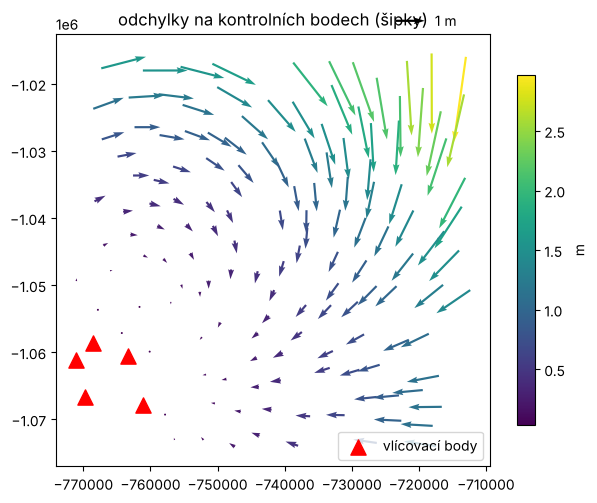

In [3]:
def fit(src, dst, kind="helmert"):
    """Parametry transformace src → dst nejmenšími čtverci (souřadnice vztažené ke středu C0)."""
    x, y = (src - C0).T
    if kind == "helmert":
        A = np.zeros((2 * len(x), 4)); A[0::2] = np.c_[x, -y, np.ones_like(x), 0 * x]; A[1::2] = np.c_[y, x, 0 * x, np.ones_like(x)]
        return kind, np.linalg.lstsq(A, dst.ravel(), rcond=None)[0]
    cols = {"afinní": [1, x, y], "affine": [1, x, y], "polynom 2": [1, x, y, x * x, x * y, y * y], "polynomial 2": [1, x, y, x * x, x * y, y * y]}[kind]
    B = np.c_[tuple(np.broadcast_to(c, x.shape) for c in cols)]
    return kind, np.linalg.lstsq(B, dst, rcond=None)[0]

def apply(model, src):
    kind, par = model; x, y = (src - C0).T
    if kind == "helmert":
        a, b, tx, ty = par; return np.c_[a * x - b * y + tx, b * x + a * y + ty]
    cols = [1, x, y] if kind in ("afinní", "affine") else [1, x, y, x * x, x * y, y * y]
    return np.c_[tuple(np.broadcast_to(c, x.shape) for c in cols)] @ par

def pick(targets):
    """Pro každý cílový bod (podíl šířky a výšky území) najde nejbližší skutečný bod."""
    x0, y0 = SRC.min(axis=0); x1, y1 = SRC.max(axis=0)
    idx = [int(np.argmin(np.hypot(SRC[:, 0] - (x0 + fx * (x1 - x0)), SRC[:, 1] - (y0 + fy * (y1 - y0))))) for fx, fy in targets]
    return np.array(list(dict.fromkeys(idx)))

LAYOUTS = {
    "rohy + střed":        pick([(0, 0), (0, 1), (1, 0), (1, 1), (0.5, 0.5)]),
    "1 ve středu":         pick([(0.5, 0.5)]),
    "shluk v rohu":        np.argsort(np.hypot(*(SRC - SRC.min(axis=0)).T))[:5],
    "jen podél linie":     pick([(f, 0.5) for f in np.linspace(0, 1, 5)]),
    "10 rovnoměrně":       pick([(fx, fy) for fx in (0.1, 0.5, 0.9) for fy in (0.1, 0.5, 0.9)] + [(0.3, 0.3)]),
}
LAYOUT = "shluk v rohu"       # ◀ parametr: jedno z rozmístění výše
gcp = LAYOUTS[LAYOUT]; chk = np.setdiff1d(np.arange(len(p)), gcp)
model = fit(SRC[gcp], DST[gcp], "helmert") if len(gcp) >= 2 else None
pred = apply(model, SRC) if model else SRC - SRC[gcp].mean(axis=0) + DST[gcp].mean(axis=0)   # jeden bod: jen posun
res = pred - DST
rmse = lambda r: np.sqrt((r ** 2).sum(axis=1).mean())
print(f"{LAYOUT}: {len(gcp)} vlícovacích, {len(chk)} kontrolních bodů")
print(f"RMSE_H na vlícovacích bodech {rmse(res[gcp]):.3f} m, na kontrolních {rmse(res[chk]):.3f} m, největší odchylka kontrolního bodu {np.hypot(*res[chk].T).max():.2f} m")
fig, ax = plt.subplots(figsize=(7, 6.5))
q_ = ax.quiver(p.sx[chk], p.sy[chk], res[chk, 0], res[chk, 1], np.hypot(*res[chk].T), cmap="viridis", scale=15, scale_units="width")
ax.scatter(p.sx[gcp], p.sy[gcp], marker="^", s=120, c="r", label="vlícovací body"); ax.quiverkey(q_, 0.85, 1.03, 1, "1 m", labelpos="E")
ax.set_aspect("equal"); ax.legend(loc="lower right"); ax.set_title("odchylky na kontrolních bodech (šipky)"); plt.colorbar(q_, label="m", shrink=0.7); plt.show()

> **✏️ Úkol 1.** Pro „shluk v rohu“ porovnej RMSE_H na vlícovacích a na kontrolních bodech. Proč jsou odchylky na vlícovacích bodech tak malé a proč z nich nelze vykázat přesnost? Kde na mapě rostou odchylky kontrolních bodů? Pak zvol „rohy + střed“: proč je teď odchylka na vlícovacích bodech větší než na kontrolních?

*Tvoje odpověď:* 

## 3. Porovnání rozmístění, polohy i výšky

GNSS dává elipsoidickou výšku h, mapy v ČR používají nadmořskou (normální) výšku v Bpv: H = h − ζ, kde ζ je výšková anomálie (v okolí Prahy kolem 44–46 m). Když z vlícovacích bodů odhadneme ζ jako konstantu, nebo jako rovinu, dostaneme výšky na kontrolních bodech. RMSE_V = √(průměr ΔH²).

Z jediného vlícovacího bodu lze polohově odhadnout jen posun. UTM a S-JTSK jsou ale vůči sobě pootočené a mají jiné měřítko, proto tu chyba vyjde v kilometrech. U bloku snímků z RTK nebo PPK je natočení i měřítko dané už polohami snímků.

                 vlícovacích  RMSE_H vlíc. (m)  RMSE_H kontr. (m)  \
rohy + střed             5.0             0.778              0.387   
1 ve středu              1.0             0.000           3062.219   
shluk v rohu             5.0             0.028              1.117   
jen podél linie          5.0             0.172              0.492   
10 rovnoměrně           10.0             0.528              0.398   

                 RMSE_V ζ konstanta (m)  RMSE_V ζ rovina (m)  
rohy + střed                      0.424                0.073  
1 ve středu                       0.433                  NaN  
shluk v rohu                      0.903                0.164  
jen podél linie                   0.433                0.352  
10 rovnoměrně                     0.424                0.055  

ζ na území: 44.11 až 45.88 m. Kdo zapomene ζ odečíst, má výšky o 45.0 m vedle.


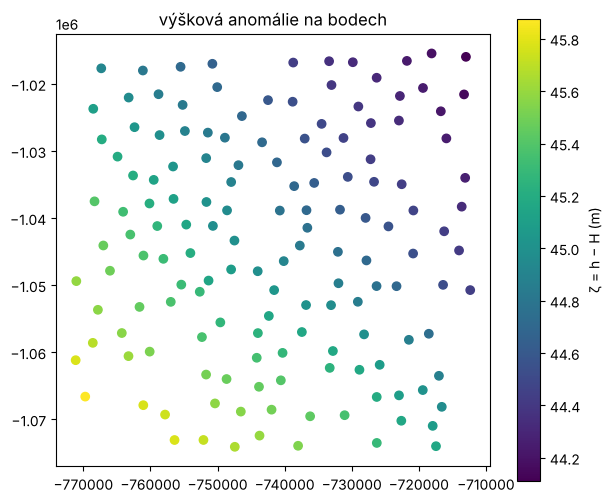

In [4]:
zeta = (p.HEL - p.VYSKA).values
x, y = (SRC - C0).T
rows = {}
for name, g in LAYOUTS.items():
    c = np.setdiff1d(np.arange(len(p)), g)
    r = (apply(fit(SRC[g], DST[g]), SRC) if len(g) >= 2 else SRC - SRC[g].mean(axis=0) + DST[g].mean(axis=0)) - DST
    const = zeta[g].mean()
    plane = np.linalg.lstsq(np.c_[np.ones(len(g)), x[g], y[g]], zeta[g], rcond=None)[0] if len(g) >= 3 else None
    rows[name] = {"vlícovacích": len(g), "RMSE_H vlíc. (m)": rmse(r[g]), "RMSE_H kontr. (m)": rmse(r[c]),
                  "RMSE_V ζ konstanta (m)": np.sqrt(((const - zeta[c]) ** 2).mean()),
                  "RMSE_V ζ rovina (m)": np.sqrt(((np.c_[np.ones(len(c)), x[c], y[c]] @ plane - zeta[c]) ** 2).mean()) if plane is not None else np.nan}
print(pd.DataFrame(rows).T.round(3))
print(f"\nζ na území: {zeta.min():.2f} až {zeta.max():.2f} m. Kdo zapomene ζ odečíst, má výšky o {zeta.mean():.1f} m vedle.")
fig, ax = plt.subplots(figsize=(7, 6)); sc = ax.scatter(p.sx, p.sy, c=zeta, cmap="viridis"); plt.colorbar(sc, label="ζ = h − H (m)"); ax.set_aspect("equal"); ax.set_title("výšková anomálie na bodech"); plt.show()

> **✏️ Úkol 2.** Které rozmístění je nejlepší polohově a které výškově? Proč body „jen podél linie“ polohu ještě drží, ale rovinu výšek (náklon) neurčí? Co dělá jediný bod ve středu a k čemu se přesto hodí, když máš RTK nebo PPK? Proč by záměna elipsoidické a nadmořské výšky byla v ČR chyba desítek metrů?

*Tvoje odpověď:* 

## 4. Kolik kontrolních bodů?

Přesnost odhadujeme z omezeného počtu kontrolních bodů, takže i samotné RMSE má nejistotu. Vybereme náhodně 12 nebo 30 kontrolních bodů mnohokrát po sobě a podíváme se, jak moc se odhad mění.

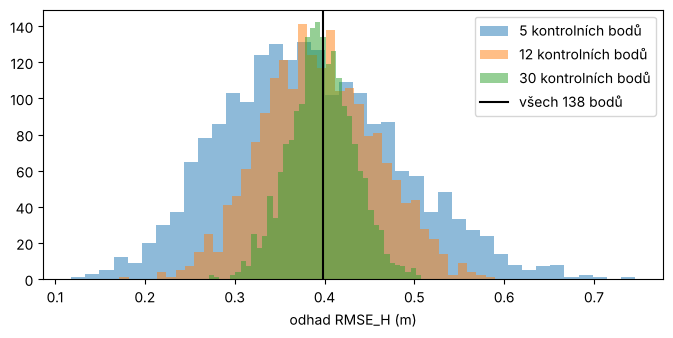

               5 bodů  12 bodů  30 bodů
5. percentil    0.237    0.294    0.337
medián          0.378    0.392    0.396
95. percentil   0.556    0.501    0.456


In [5]:
LAYOUT_N = "10 rovnoměrně"    # ◀ parametr: rozmístění vlícovacích bodů
COUNTS = [5, 12, 30]          # ◀ parametr: počty kontrolních bodů
DRAWS = 2000                  # ◀ parametr: počet náhodných výběrů
g = LAYOUTS[LAYOUT_N]; c = np.setdiff1d(np.arange(len(p)), g)
r = np.hypot(*(apply(fit(SRC[g], DST[g]), SRC) - DST).T)[c]
rng = np.random.default_rng(1)
est = {n: np.array([np.sqrt((rng.choice(r, n, replace=False) ** 2).mean()) for _ in range(DRAWS)]) for n in COUNTS if n <= len(r)}
plt.figure(figsize=(8, 3.5))
for n, e in est.items():
    plt.hist(e, 40, alpha=0.5, label=f"{n} kontrolních bodů")
plt.axvline(np.sqrt((r ** 2).mean()), color="k", label=f"všech {len(r)} bodů"); plt.xlabel("odhad RMSE_H (m)"); plt.legend(); plt.show()
print(pd.DataFrame({f"{n} bodů": {"5. percentil": np.percentile(e, 5), "medián": np.median(e), "95. percentil": np.percentile(e, 95)} for n, e in est.items()}).round(3))

> **✏️ Úkol 3.** Jak široké je rozmezí odhadu RMSE_H (5. až 95. percentil) s 5, 12 a 30 kontrolními body? Proč ASPRS požaduje aspoň 30 kontrolních bodů? Proč musí být kontrolní body rozmístěné po celém území a ne třeba jen u silnice?

*Tvoje odpověď:* 

## 5. Složitější transformace a málo bodů

Helmertova transformace má 4 parametry, afinní 6 (navíc dvě různá měřítka a zkosení) a polynom 2. stupně 12. Víc parametrů se k vlícovacím bodům přizpůsobí lépe. Jestli to pomůže i na kontrolních bodech, záleží na tom, jestli skutečný rozdíl mezi systémy takový tvar má, a na tom, kolik je vlícovacích bodů. Vlícovací body losujeme náhodně a díváme se na medián i na 90. percentil (nepříznivé losování).

RMSE_H na kontrolních bodech (m), medián:
                  helmert  afinní  polynom 2
vlícovacích bodů                            
3                   0.572   0.773        NaN
4                   0.538   0.653        NaN
6                   0.488   0.563      0.371
8                   0.461   0.531      0.202
12                  0.446   0.484      0.147
20                  0.426   0.447      0.124
40                  0.417   0.429      0.105
90. percentil:
                  helmert  afinní  polynom 2
vlícovacích bodů                            
3                   0.800   2.183        NaN
4                   0.717   0.971        NaN
6                   0.605   0.745      1.775
8                   0.554   0.676      0.373
12                  0.501   0.588      0.218
20                  0.461   0.512      0.160
40                  0.442   0.458      0.120


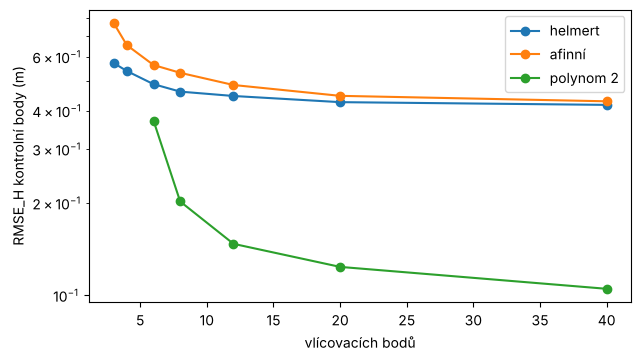

In [6]:
KINDS = ["helmert", "afinní", "polynom 2"]
N_GCP = [3, 4, 6, 8, 12, 20, 40]   # ◀ parametr: počty vlícovacích bodů
REPEAT = 200                  # ◀ parametr: počet losování pro každý počet
need = {"helmert": 2, "afinní": 3, "polynom 2": 6}
out = {k: [] for k in KINDS}
for n in N_GCP:
    for k in KINDS:
        vals = []
        for _ in range(REPEAT):
            g = rng.choice(len(p), n, replace=False); c = np.setdiff1d(np.arange(len(p)), g)
            if n < need[k]: break
            vals.append(rmse(apply(fit(SRC[g], DST[g], k), SRC[c]) - DST[c]))
        out[k].append((np.median(vals), np.percentile(vals, 90)) if vals else (np.nan, np.nan))
tab = pd.DataFrame({k: [v[0] for v in out[k]] for k in KINDS}, index=pd.Index(N_GCP, name="vlícovacích bodů"))
p90 = pd.DataFrame({k: [v[1] for v in out[k]] for k in KINDS}, index=tab.index)
print("RMSE_H na kontrolních bodech (m), medián:"); print(tab.round(3)); print("90. percentil:"); print(p90.round(3))
tab.plot(marker="o", logy=True, figsize=(7, 3.8), ylabel="RMSE_H kontrolní body (m)"); plt.show()

> **✏️ Úkol 4.** Která transformace je nejlepší se 3–4 body a která se 40 body? Proč je afinní transformace při všech počtech o něco horší než Helmertova, kdežto polynom 2. stupně je od 8 bodů výrazně lepší? Co to říká o tvaru skutečného rozdílu mezi S-JTSK a UTM? Porovnej 90. percentil polynomu se 6 body s mediánem: jak riskantní je model, který má skoro tolik parametrů jako podmínek? Podle čeho bys v praxi volil model transformace nebo počet parametrů autokalibrace kamery?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Bodová pole: © ČÚZK, služba https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer (CC BY 4.0); geodetické údaje bodů na https://geoportal.cuzk.gov.cz
- ASPRS (2023). *ASPRS Positional Accuracy Standards for Digital Geospatial Data*, Edition 2, Version 1.0 (RMSE_H, RMSE_V, nejméně 30 kontrolních bodů).
- Sanz-Ablanedo, E., Chandler, J. H., Rodríguez-Pérez, J. R., Ordóñez, C. (2018). Accuracy of Unmanned Aerial Vehicle (UAV) and SfM Photogrammetry Survey as a Function of the Number and Location of Ground Control Points Used. *Remote Sensing* 10(10), 1606.
- Hofmann-Wellenhof, B., Lichtenegger, H., Wasle, E. (2008). *GNSS – Global Navigation Satellite Systems*. Springer (elipsoidická a normální výška, výšková anomálie).

### Jak citovat

OpenSkyLab (2026). Vlícovací a kontrolní body: přesnost transformace na skutečném bodovém poli [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/gcp_accuracy_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*